In [2]:
%pip install pandas numpy matplotlib seaborn

  Using cached pandas-2.3.3-cp310-cp310-macosx_11_0_arm64.whl (10.8 MB)
  Using cached numpy-2.2.6-cp310-cp310-macosx_14_0_arm64.whl (5.3 MB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 3.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 5.7 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.3/506.3 kB 4.5 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.1/64.1 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 4.3 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 4.5 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.4/253.4 kB 3.3 MB/s eta 0:00:00a 0:00:01

[notice] A new release of pip available: 22.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated

In [ ]:
# Import libraries and load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("combined_classification_cleaned_df.csv")

sns.set_theme(style="whitegrid")

print(df.shape)
df.head()

(3113, 32)


,Unnamed: 0,ia_no,incident_type_x,received_date_x,occurred_date_x,allegation_x,finding_x,disposition_x,label,narrative_x,...,Act: Days/hours suspended,allegation_standardized,bias_label,alg,alg_names,sev,conf,lang,quote,problems
0,0,IAD2011-0003,Citizen complaint,1/5/2011,6/18/2009,Use of Force,Exonerated,Exonerated,NO,Complainant stated that Sgt. Det. Terestre and...,...,NaN,Use of Force,False,[17],Use of Force,3.3,5.0,NaN,Sgt. Terestre grabbed him by the throat and ch...,NaN
1,1,IAD2011-0011,Citizen complaint,1/7/2011,1/3/2011,Neg.Duty/Unreasonable Judge | Jr. Neg.Duty/Unr...,Exonerated,Exonerated,NO,[NAME] came in to E‐13 and requested to file a...,...,NaN,Neglect of Duty / Unreasonable Judgment | UNMA...,False,"[1, 18]",Neglect of Duty / Unreasonable Judgment|Search...,3.1,2.0,NaN,they searched him,NaN
2,2,IAD2011-0012,Citizen complaint,1/7/2011,10/12/2008,Neg.Duty/Unreasonable Judge,Not Sustained,Not Sustained,NO,Complainant states he was being transported in...,...,NaN,Neglect of Duty / Unreasonable Judgment,False,"[20, 1]",Prisoner Care|Neglect of Duty / Unreasonable J...,3.2,3.0,NaN,drove in an erratic manner causing him to fall...,NaN
3,3,IAD2011-0013,Citizen complaint,1/7/2011,10/27/2010,Respectful Treatment,Not Sustained,Not Sustained,NO,In October of 2010 i was on Warren St. by Roxb...,...,NaN,Respectful Treatment,False,[2],Respectful Treatment,2.1,4.0,NaN,give me your fucking license and registration ...,NaN
4,4,IAD2011-0017,Internal investigation,1/10/2011,1/9/2011,Neg.Duty/Unreasonable Judge | Conformance to Laws,Not Sustained,Not Sustained,NO,"On 01/09/11 Lt. John Earley, ID#12114, was arr...",...,NaN,Neglect of Duty / Unreasonable Judgment | Conf...,False,"[44, 4]",Alcohol off Duty|Conformance to Laws,1.4,5.0,P,"arrested in Haverhill, NH by NH State Police f...",NaN


In [ ]:
# Create severity levels
df["severity_level"] = (
    df["sev"].astype(str)
    .str.extract(r"^([123])\.")[0]
    .map({
        "1": "Level 1",
        "2": "Level 2",
        "3": "Level 3"
    })
    .fillna("Unclear")
)

severity_order = [
    "Level 1", "Level 2", "Level 3", "Unclear"
]

severity_colors = {
    "Level 1": "#6BAED6",
    "Level 2": "#FDAE6B",
    "Level 3": "#DE2D26",
    "Unclear": "#BDBDBD"
}

In [ ]:
# Split by allegation classifications
def split_allegations(value):
    if pd.isna(value):
        return set()

    return {
        label.strip()
        for label in str(value).split("|")
        if label.strip()
    }

df["llm_allegations"] = df["alg_names"].apply(
    split_allegations
)

df["bpd_allegations"] = df["allegation_standardized"].apply(
    split_allegations
)

In [ ]:
# Severity and sublevel distributions
# Understand the distribution of alleged misconduct 
# across your severity classification framework.

In [ ]:
# Severity level distribution
severity_counts = (
    df["severity_level"]
    .value_counts()
    .reindex(severity_order, fill_value=0)
)

severity_summary = pd.DataFrame({
    "Count": severity_counts,
    "Percentage": severity_counts / len(df) * 100
})

display(severity_summary.round(2))

,Count,Percentage
severity_level,,
Level 1,806,25.89
Level 2,1552,49.86
Level 3,629,20.21
Unclear,126,4.05


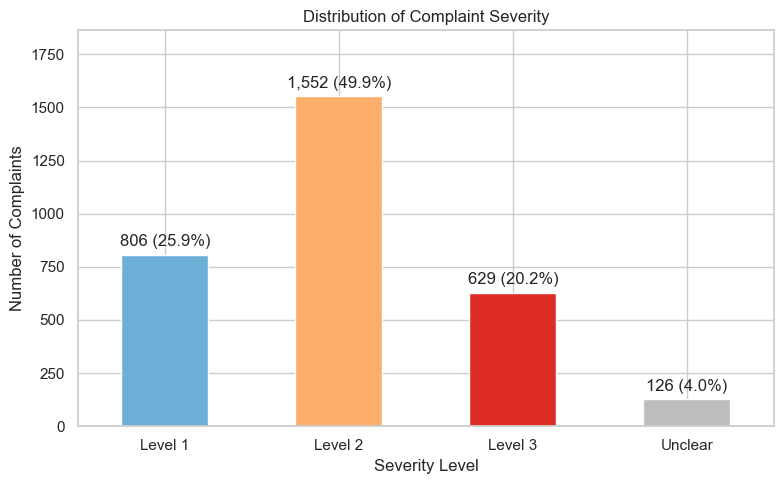

In [ ]:
# Visualization for severity level distribution
ax = severity_counts.plot(
    kind="bar",
    figsize=(8, 5),
    color=list(severity_colors.values())
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f"{n:,} ({n / len(df):.1%})"
        for n in severity_counts
    ],
    padding=4
)

plt.title("Distribution of Complaint Severity")
plt.xlabel("Severity Level")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=0)
plt.ylim(0, severity_counts.max() * 1.2)
plt.tight_layout()
plt.show()

In [ ]:
# Severity sublevel distribution
sublevel_counts = (
    df["sev"]
    .astype(str)
    .value_counts()
    .sort_index()
)

# Exclude unclear severity
sublevel_counts = sublevel_counts[
    sublevel_counts.index.str.match(r"^[123]\.\d+$")
]

sublevel_summary = pd.DataFrame({
    "Count": sublevel_counts,
    "Percentage": sublevel_counts / len(df) * 100
})

display(sublevel_summary.round(2))

,Count,Percentage
sev,,
1.1,79,2.54
1.2,254,8.16
1.3,172,5.53
1.4,94,3.02
1.5,207,6.65
2.1,562,18.05
2.2,343,11.02
2.3,352,11.31
2.4,295,9.48


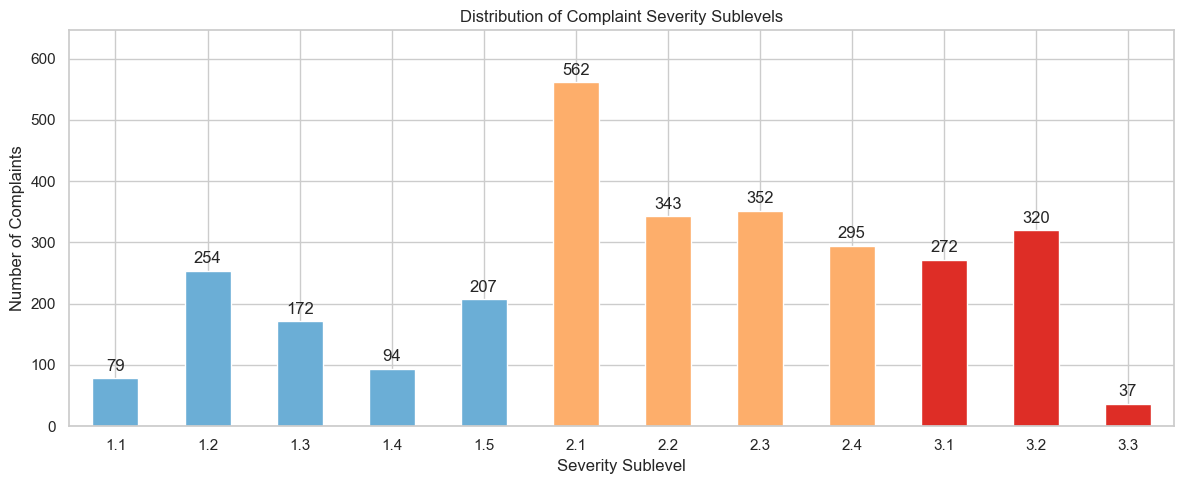

In [ ]:
# Visualization for severity sublevel distribution
sublevel_colors = [
    severity_colors[f"Level {level[0]}"]
    for level in sublevel_counts.index
]

ax = sublevel_counts.plot(
    kind="bar",
    figsize=(12, 5),
    color=sublevel_colors
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Distribution of Complaint Severity Sublevels")
plt.xlabel("Severity Sublevel")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=0)
plt.ylim(0, sublevel_counts.max() * 1.15)
plt.tight_layout()
plt.show()


In [ ]:
# Most common classified allegations
# Objective: Identify the most frequently occurring types of 
# alleged police misconduct based on the LLM classifications

In [11]:
# Calculate counts and percentages
allegation_counts = (
    df["llm_allegations"]
    .explode()
    .value_counts()
)

allegation_summary = pd.DataFrame({
    "Count": allegation_counts,
    "Percentage of Complaints": (
        allegation_counts / len(df) * 100
    )
})

display(allegation_summary.round(2))

,Count,Percentage of Complaints
llm_allegations,,
Respectful Treatment,1182,37.97
Neglect of Duty / Unreasonable Judgment,548,17.60
Use of Force,492,15.80
Abuse of Process,380,12.21
Police Service,359,11.53
Conduct Unbecoming,337,10.83
Harassment,302,9.70
Bias / Discriminatory Treatment,228,7.32
Self Identification,206,6.62


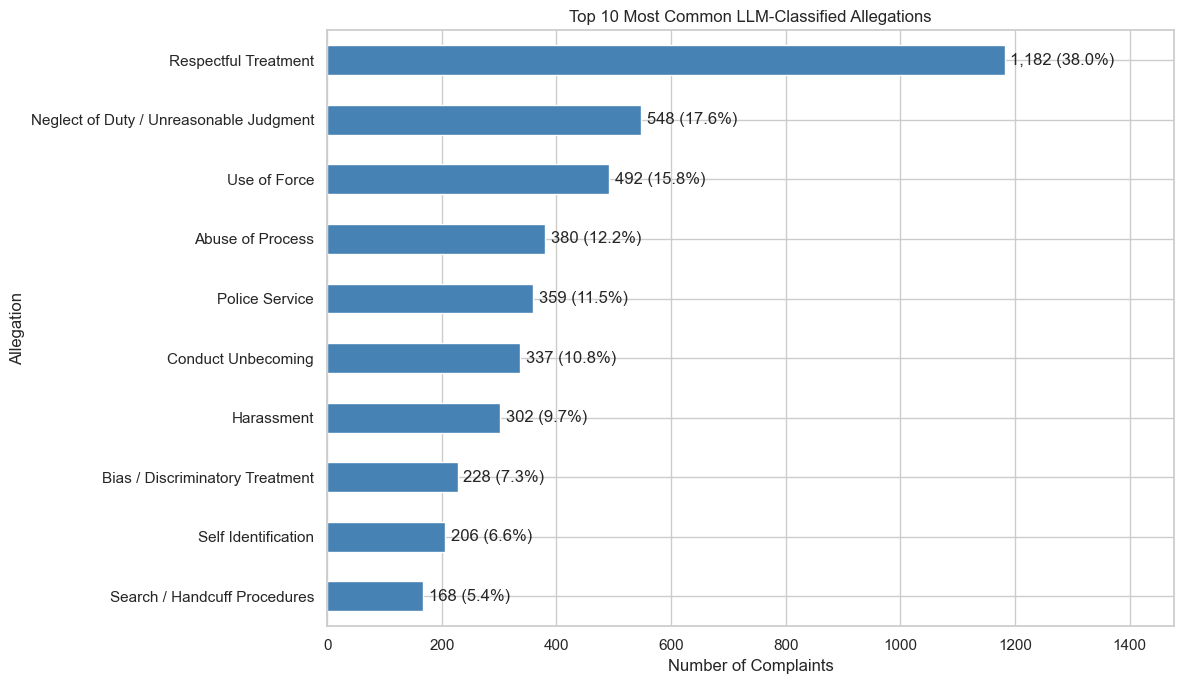

In [12]:
# Visualize the top 10 allegations
top_10 = allegation_counts.head(10).sort_values()

ax = top_10.plot(
    kind="barh",
    figsize=(12, 7),
    color="steelblue"
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f"{n:,} ({n / len(df):.1%})"
        for n in top_10
    ],
    padding=4
)

plt.title("Top 10 Most Common LLM-Classified Allegations")
plt.xlabel("Number of Complaints")
plt.ylabel("Allegation")
plt.xlim(0, top_10.max() * 1.25)
plt.tight_layout()
plt.show()

In [ ]:
# Severity of additional allegations
# Identify allegations assigned by the LLM that were not 
# present in the original BPD classifications and examine 
# the severity of complaints containing those allegations.

In [13]:
# Filter comparable complaints
comparison_df = df[
    df["bpd_allegations"].apply(
        lambda x: bool(x) and "UNMAPPED" not in x
    ) &
    df["llm_allegations"].apply(bool)
].copy()

print("Total complaints:", len(df))
print("Comparable complaints:", len(comparison_df))
print("Excluded complaints:", len(df) - len(comparison_df))

Total complaints: 3113
Comparable complaints: 2352
Excluded complaints: 761


In [14]:
# Identify additional allegations
comparison_df["additional_allegations"] = (
    comparison_df.apply(
        lambda row: (
            row["llm_allegations"] -
            row["bpd_allegations"]
        ),
        axis=1
    )
)

comparison_df["num_additional"] = (
    comparison_df["additional_allegations"].apply(len)
)

comparison_df["has_additional"] = (
    comparison_df["num_additional"] > 0
)

In [15]:
# Percentage of complaints with additional allegations by severity
additional_summary = (
    comparison_df.groupby("severity_level")
    .agg(
        total_complaints=("ia_no", "count"),
        complaints_with_additional=("has_additional", "sum"),
        total_additional_allegations=("num_additional", "sum")
    )
    .reindex(severity_order)
)

additional_summary["percentage_with_additional"] = (
    additional_summary["complaints_with_additional"] /
    additional_summary["total_complaints"] * 100
)

display(additional_summary.round(2))

,total_complaints,complaints_with_additional,total_additional_allegations,percentage_with_additional
severity_level,,,,
Level 1,601,559,847,93.01
Level 2,1250,1060,1616,84.80
Level 3,464,359,589,77.37
Unclear,37,30,36,81.08


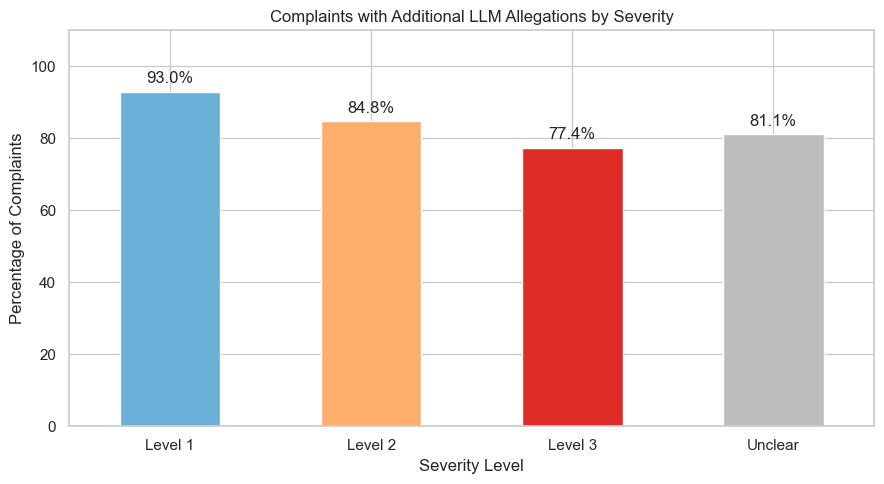

In [16]:
# Visualization for percentage of complaints with additional allegations by severity
ax = additional_summary["percentage_with_additional"].plot(
    kind="bar",
    figsize=(9, 5),
    color=list(severity_colors.values())
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=4
)

plt.title("Complaints with Additional LLM Allegations by Severity")
plt.xlabel("Severity Level")
plt.ylabel("Percentage of Complaints")
plt.xticks(rotation=0)
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

In [17]:
# Most common additional allegations by severity
additional_exploded = (
    comparison_df
    .explode("additional_allegations")
    .reset_index(drop=True)
)

additional_severity = pd.crosstab(
    additional_exploded["additional_allegations"],
    additional_exploded["severity_level"]
)

additional_severity = additional_severity.reindex(
    columns=severity_order,
    fill_value=0
)

# Select the top 10 additional allegations
top_additional = (
    additional_severity.sum(axis=1)
    .nlargest(10)
    .index
)

additional_top_10 = additional_severity.loc[top_additional]

display(additional_top_10)

severity_level,Level 1,Level 2,Level 3,Unclear
additional_allegations,,,,
Abuse of Process,17,188,87,3
Police Service,5,261,8,0
Harassment,1,213,28,1
Respectful Treatment,4,144,39,0
Bias / Discriminatory Treatment,0,151,27,0
Conduct Unbecoming,16,143,13,2
Use of Force,0,6,135,0
Leave / Attendance,139,0,0,0
Conflicts / Off-Duty Situations,25,84,23,4


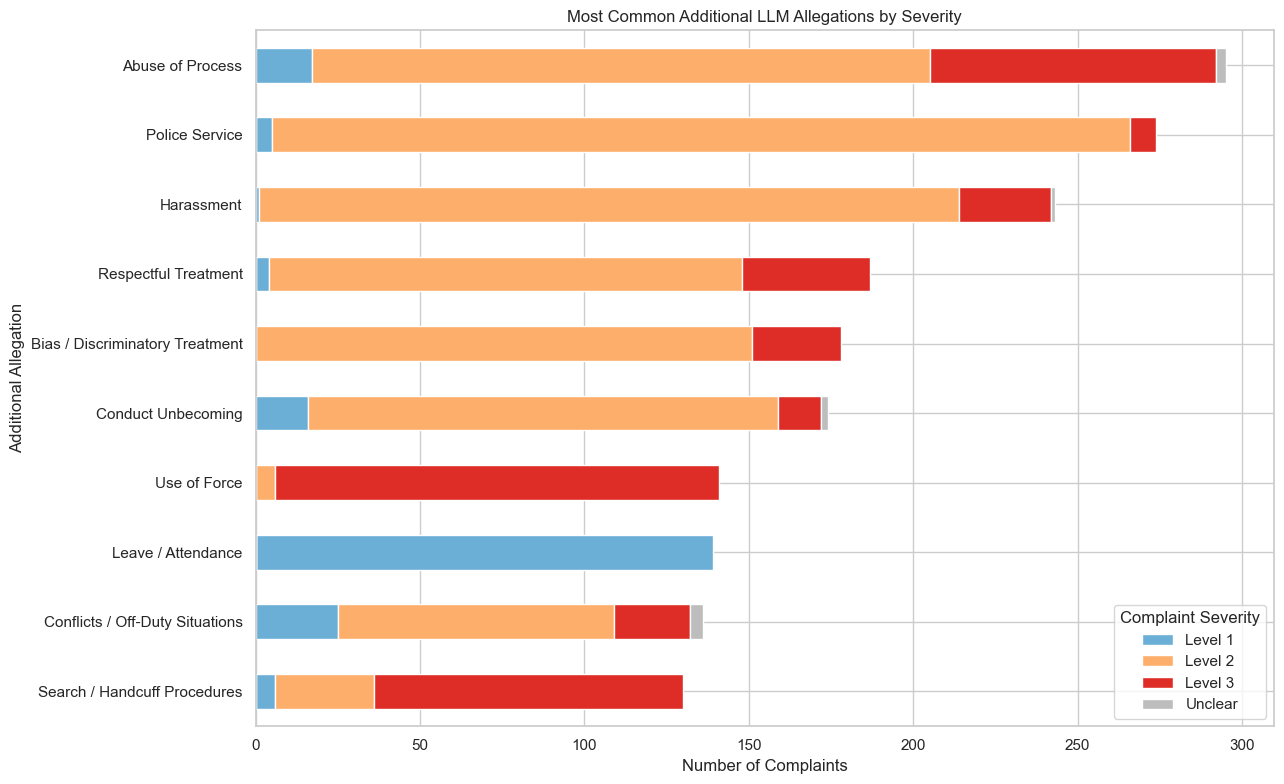

In [18]:
# Visualization - Stacked horizontal bar chart
ax = additional_top_10.iloc[::-1].plot(
    kind="barh",
    stacked=True,
    figsize=(13, 8),
    color=list(severity_colors.values())
)

plt.title("Most Common Additional LLM Allegations by Severity")
plt.xlabel("Number of Complaints")
plt.ylabel("Additional Allegation")
plt.legend(title="Complaint Severity")
plt.tight_layout()
plt.show()

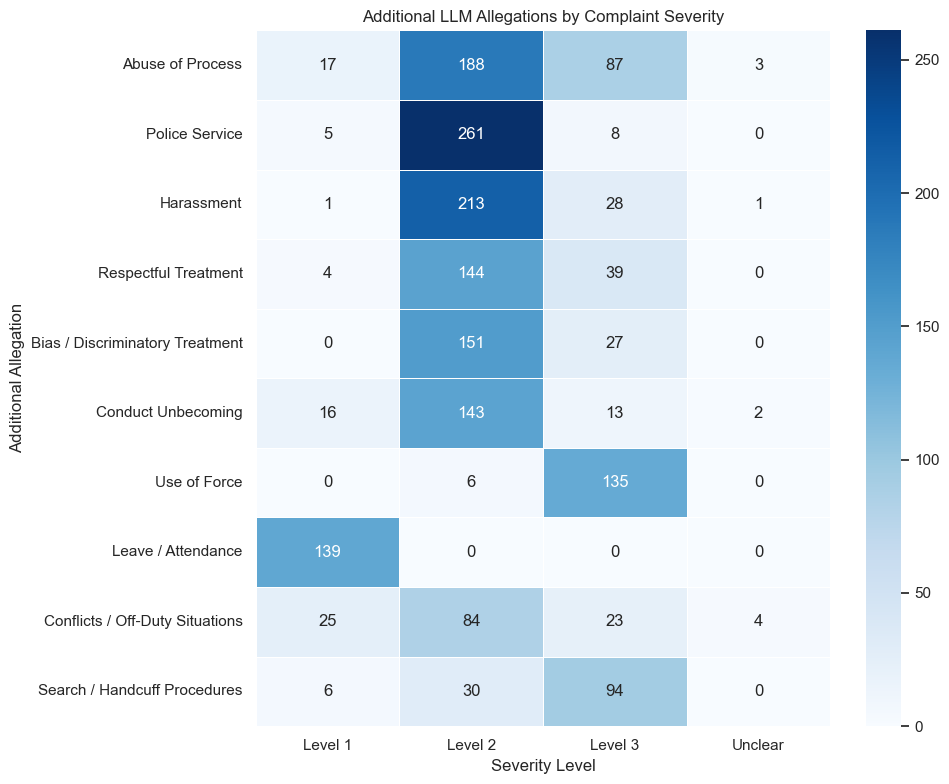

In [19]:
# Visualization - heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    additional_top_10,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Additional LLM Allegations by Complaint Severity")
plt.xlabel("Severity Level")
plt.ylabel("Additional Allegation")
plt.tight_layout()
plt.show()

In [20]:
# Additional allegations within Level 3 complaints
level3_df = comparison_df[
    comparison_df["severity_level"] == "Level 3"
]

level3_additional = (
    level3_df["additional_allegations"]
    .explode()
    .value_counts()
)

level3_summary = pd.DataFrame({
    "Count": level3_additional,
    "Percentage of Level 3 Complaints": (
        level3_additional / len(level3_df) * 100
    )
})

display(level3_summary.head(10).round(2))

,Count,Percentage of Level 3 Complaints
additional_allegations,,
Use of Force,135,29.09
Search / Handcuff Procedures,94,20.26
Abuse of Process,87,18.75
Respectful Treatment,39,8.41
Harassment,28,6.03
Bias / Discriminatory Treatment,27,5.82
Conflicts / Off-Duty Situations,23,4.96
Neglect of Duty / Unreasonable Judgment,22,4.74
Self Identification,21,4.53


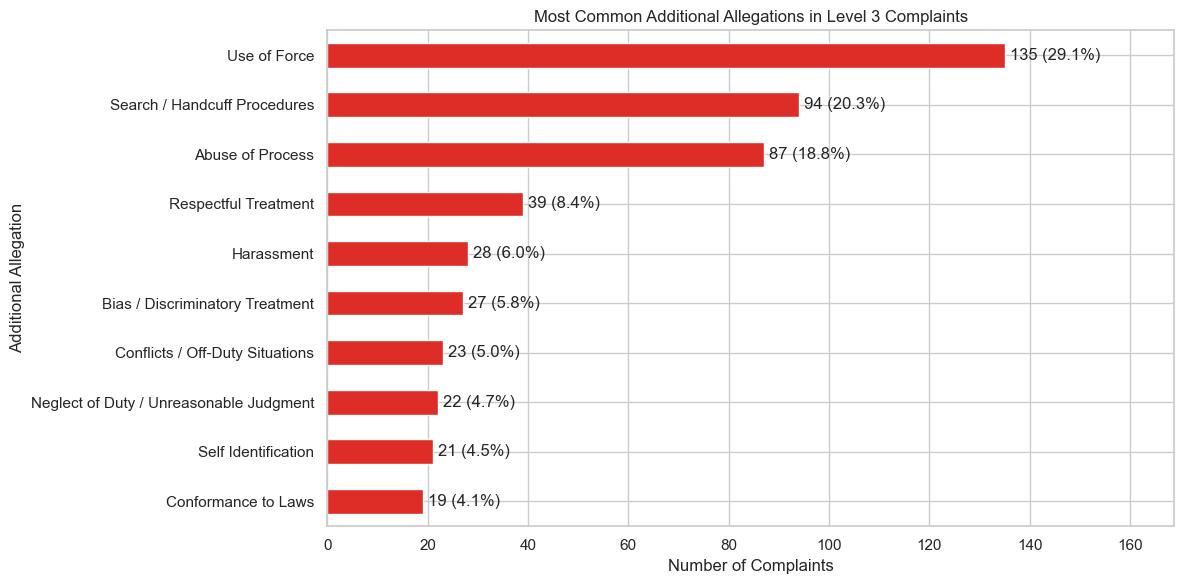

In [21]:
# Visualization for additional allegations within Level 3 complaints
top_level3 = level3_additional.head(10).sort_values()

ax = top_level3.plot(
    kind="barh",
    figsize=(12, 6),
    color=severity_colors["Level 3"]
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f"{n} ({n / len(level3_df):.1%})"
        for n in top_level3
    ],
    padding=4
)

plt.title("Most Common Additional Allegations in Level 3 Complaints")
plt.xlabel("Number of Complaints")
plt.ylabel("Additional Allegation")
plt.xlim(0, top_level3.max() * 1.25)
plt.tight_layout()
plt.show()